# RoadScan AI | Dataset Preparation & Quality Assurance

**Senior Project I · Preprocessing methodology · Prepared dataset v1.0**

This notebook documents the complete dataset-preparation pipeline used for the five-class road-damage detector. It replaces the original exploratory notebook with a **concise, reproducible sequence**: source inspection → class mapping → annotation conversion and cleaning → split creation → exact-image deduplication → final validation.

**Status:** Dataset assembled and structurally checked. **Model training has not started.** The output is `Datasets/RoadScan_Final/` with **39,040 images**.

> **How to use:** Open this notebook from the `RoadVision AI` project root. The existing `Datasets/` folders, `additional_review.csv`, and `duplicate_review.csv` are required for full re-execution. All destructive/build actions are **disabled by default**, so reviewing or running the notebook will not overwrite your work. GitHub may contain only the code and review metadata; the full dataset is stored separately.

## 1 · Dataset design and class definitions

Two prepared sources are combined:

| Source | Role | Key preprocessing |
|---|---|---|
| **RDD2022 (`RDD_SPLIT`)** | Road cracks and ordinary potholes | Original labels remapped to project classes; excluded one source class; invalid zero-width box removed |
| **Additional annotated pothole dataset** | Ordinary and water-filled potholes | XML annotations preferred over inconsistent TXT labels; 1,157 objects manually classified; faulty images/boxes excluded |

**Target YOLO classes**

| ID | Class |
|---:|---|
| 0 | Longitudinal Crack |
| 1 | Transverse Crack |
| 2 | Alligator Crack |
| 3 | Pothole |
| 4 | Water-Filled Pothole |

The same class IDs are used for all train, validation, and test labels. Only the **image + matching YOLO `.txt` annotation** pair is considered a unit of data.

## 2 · Project paths and execution settings

Paths are relative to the notebook's working directory (the project root), not to a specific Windows username. Set any rebuild flag to `True` **only to intentionally regenerate a missing output folder**. Existing outputs are protected against overwriting.

In [ ]:
from collections import Counter, defaultdict
from pathlib import Path
import hashlib
import math
import random
import shutil
import xml.etree.ElementTree as ET

import pandas as pd

ROOT = Path.cwd().resolve()  # Open Jupyter from the RoadVision AI project folder
DATA = ROOT / "Datasets"
RDD_RAW = DATA / "RDD_SPLIT"
RDD_CLEAN = DATA / "RDD_CLEANED"
ADDITIONAL_RAW = DATA / "Annotated_Additional_Dataset"
ADDITIONAL_REVIEWED = DATA / "Additional_YOLO_REVIEWED"
FINAL = DATA / "RoadScan_Final"
CLASS_REVIEW = ROOT / "additional_review.csv"
DUPLICATE_REVIEW = ROOT / "duplicate_review.csv"
SPLITS = ("train", "val", "test")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}
CLASS_NAMES = {
    0: "Longitudinal Crack", 1: "Transverse Crack",
    2: "Alligator Crack", 3: "Pothole", 4: "Water-Filled Pothole",
}

# Safety switches: all remain False when documenting the completed project.
REBUILD_RDD_LABELS = False
REBUILD_ADDITIONAL_LABELS = False
REBUILD_FINAL_DATASET = False
RECOMPUTE_MANIFEST = False  # SHA-256 scan can be expensive on ~39,000 images

print("Project:", ROOT)
for label, path in [
    ("RDD source", RDD_RAW), ("RDD cleaned", RDD_CLEAN),
    ("Additional source", ADDITIONAL_RAW),
    ("Additional reviewed", ADDITIONAL_REVIEWED),
    ("Final dataset", FINAL),
    ("Classification decisions", CLASS_REVIEW),
    ("Duplicate decisions", DUPLICATE_REVIEW),
]:
    print(f"{label:26}: {'available' if path.exists() else 'not present'}")

## 3 · RDD2022: audit, remap, and clean annotations

The completed project used the following **source-label mapping**:

`0 → 0`, `1 → 1`, `2 → 2`, `4 → 3`; **original source class `3` was excluded**. This mapping describes the procedure used; its semantic correctness must still be verified against the original dataset's class definitions before final research evaluation.

RDD's existing train/val/test split is retained. Empty labels are kept (they may represent negative examples), but labels made empty by excluding class `3` warrant a separate visual audit. One confirmed zero-width annotation was removed from `Japan_001265.txt`. Very small boundary-rounding overflows (at most approximately `5e-7`) are accepted with a `1e-6` tolerance.

In [ ]:
RDD_CLASS_MAP = {0: 0, 1: 1, 2: 2, 4: 3}
INVALID_RDD_LINE = "2 0.330000 0.790833 0.000000 0.001667"


def write_clean_rdd_labels():
    """Reproduce RDD_CLEANED/labels directly from RDD_SPLIT/labels."""
    assert RDD_RAW.is_dir(), "Original RDD_SPLIT folder is missing"
    assert not RDD_CLEAN.exists(), "RDD_CLEANED already exists: refusing to overwrite"
    dropped_categories = Counter()
    malformed_removed = 0

    for split in SPLITS:
        src = RDD_RAW / split / "labels"
        dst = RDD_CLEAN / split / "labels"
        for label_file in sorted(src.rglob("*.txt")):
            cleaned = []
            for line in label_file.read_text(encoding="utf-8").splitlines():
                if not line.strip():
                    continue
                parts = line.split()
                old_id = int(parts[0])
                if old_id == 3:
                    dropped_categories[split] += 1
                    continue
                if old_id not in RDD_CLASS_MAP:
                    raise ValueError(f"Unexpected RDD class {old_id}: {label_file}")
                parts[0] = str(RDD_CLASS_MAP[old_id])
                mapped_line = " ".join(parts)
                if label_file.stem.lower() == "japan_001265" and mapped_line == INVALID_RDD_LINE:
                    malformed_removed += 1
                    continue
                cleaned.append(mapped_line)
            target = dst / label_file.relative_to(src)
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_text("\n".join(cleaned) + ("\n" if cleaned else ""), encoding="utf-8")

    assert malformed_removed == 1, f"Expected to remove 1 invalid box; got {malformed_removed}"
    print("RDD clean labels built; excluded source-class-3 boxes:", dict(dropped_categories))
    print("Zero-width boxes removed:", malformed_removed)


if REBUILD_RDD_LABELS:
    write_clean_rdd_labels()
else:
    print("Rebuild skipped; using existing RDD_CLEANED labels.")

## 4 · Additional dataset: annotation source and human review

The additional dataset contains 713 XML annotation files and 1,157 labeled object instances. Visual comparisons showed substantial differences between some supplied TXT bounding boxes and XML bounding boxes; **XML was selected as the conversion source**.

The per-object `additional_review.csv` records the human decision to assign **class 3 (ordinary)** or **class 4 (water-filled)**. Objects are keyed by `(filename, object_index)`; no duplicate keys or unclassified objects were left in the completed review.

The review CSV is an important artifact: the notebook **uses those recorded decisions** rather than asking someone to repeat the manual labeling.

In [ ]:
if CLASS_REVIEW.exists():
    review = pd.read_csv(CLASS_REVIEW)
    assert not review.duplicated(["filename", "object_index"]).any()
    assert review["final_class"].isin([3, 4]).all()
    assert len(review) == 1157, "Review CSV differs from the documented v1.0 source"

    print("Reviewed objects:", len(review))
    print("Manual classifications:", dict(Counter(review["final_class"].astype(int))))
    print("Unclassified:", review["final_class"].isna().sum())
else:
    print("additional_review.csv is required for reproduction; not available here.")

## 5 · XML → YOLO and quality-control exclusions

Conversion formula (XML pixel coordinates → normalized YOLO):

- `x_center = (xmin + xmax) / (2 × image_width)`
- `y_center = (ymin + ymax) / (2 × image_height)`
- `box_width = (xmax − xmin) / image_width`
- `box_height = (ymax − ymin) / image_height`

**Documented corrections:** Four images with invalid XML boxes (`Pothole-261`, `262`, `268`, `271`) were excluded; three visually questionable images (`Pothole-609`, `031`, `659`) were quarantined. One duplicate Class-4 annotation was deleted from `Pothole-009`. The reviewed dataset therefore contains **706 images**, **713 class-3 objects**, and **431 class-4 objects**.

The original XML/IMG dataset and the human decision CSV remain unchanged. This condensed rebuild generates only the reviewed output folder when explicitly enabled; it does not recreate each exploratory intermediate folder.

In [ ]:
BAD_XML_IMAGES = {"pothole-261", "pothole-262", "pothole-268", "pothole-271"}
QUESTIONABLE_IMAGES = {"pothole-609", "pothole-031", "pothole-659"}
SKIP_ADDITIONAL = BAD_XML_IMAGES | QUESTIONABLE_IMAGES
DUPLICATE_BOX_LINE = "4 0.235057 0.356796 0.266559 0.121359"


def write_reviewed_additional():
    """Recreate Additional_YOLO_REVIEWED from XML + saved object-class decisions."""
    import cv2

    assert not ADDITIONAL_REVIEWED.exists(), "Reviewed output already exists: refusing overwrite"
    assert (ADDITIONAL_RAW / "XML").is_dir() and (ADDITIONAL_RAW / "IMG").is_dir()
    review = pd.read_csv(CLASS_REVIEW)
    assert len(review) == 1157
    assert review["final_class"].isin([3, 4]).all()
    assert not review.duplicated(["filename", "object_index"]).any()
    decisions = {
        (str(r.filename).lower(), int(r.object_index)): int(r.final_class)
        for r in review.itertuples()
    }
    image_index = {
        p.stem.lower(): p for p in (ADDITIONAL_RAW / "IMG").rglob("*")
        if p.suffix.lower() in IMAGE_EXTENSIONS
    }

    prepared, counts = [], Counter()
    for xml_path in sorted((ADDITIONAL_RAW / "XML").rglob("*.xml")):
        name = xml_path.stem.lower()
        if name in SKIP_ADDITIONAL:
            continue
        image_path = image_index[name]
        image = cv2.imread(str(image_path))
        if image is None:
            raise ValueError(f"Unreadable image: {image_path}")
        height, width = image.shape[:2]
        root = ET.parse(xml_path).getroot()
        assert (width, height) == (
            int(root.findtext("size/width")), int(root.findtext("size/height"))
        ), f"XML / image dimensions disagree: {name}"
        lines = []
        for object_index, obj in enumerate(root.findall("object")):
            cls = decisions[(name, object_index)]
            box = obj.find("bndbox")
            xmin, ymin, xmax, ymax = [float(box.findtext(k)) for k in
                                       ("xmin", "ymin", "xmax", "ymax")]
            if not (0 <= xmin < xmax <= width and 0 <= ymin < ymax <= height):
                raise ValueError(f"Out-of-image XML box: {name}, object {object_index}")
            xc, yc = (xmin + xmax) / (2 * width), (ymin + ymax) / (2 * height)
            w, h = (xmax - xmin) / width, (ymax - ymin) / height
            lines.append(f"{cls} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")

        if name == "pothole-009":
            assert len(lines) == 2 and lines[1] == DUPLICATE_BOX_LINE
            lines.pop(1)
        for line in lines:
            counts[int(line.split()[0])] += 1
        prepared.append((image_path, lines))

    assert len(prepared) == 706
    assert counts == Counter({3: 713, 4: 431})
    (ADDITIONAL_REVIEWED / "images").mkdir(parents=True)
    (ADDITIONAL_REVIEWED / "labels").mkdir(parents=True)
    for image_path, lines in prepared:
        shutil.copy2(image_path, ADDITIONAL_REVIEWED / "images" / image_path.name)
        label_path = ADDITIONAL_REVIEWED / "labels" / f"{image_path.stem}.txt"
        label_path.write_text("\n".join(lines) + ("\n" if lines else ""), encoding="utf-8")
    print("Additional reviewed dataset built:", len(prepared), "images;", dict(counts), "objects")


if REBUILD_ADDITIONAL_LABELS:
    write_reviewed_additional()
else:
    print("Rebuild skipped; using existing Additional_YOLO_REVIEWED.")

**Representative annotated examples from the original review notebook**  
Green boxes identify the target class in each example; other classes, where present, were shown in a different color. These are illustrative review snapshots, not evidence that every annotation is perfect.

| Ordinary pothole — Class 3 | Water-filled potholes — Class 4 |
|:---:|:---:|
| 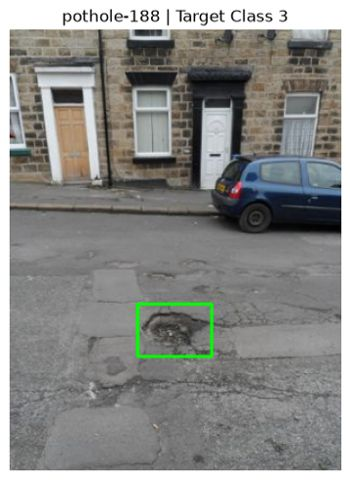 | 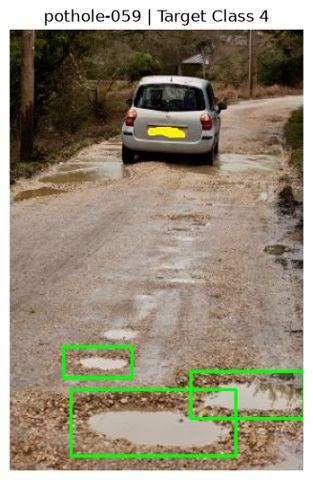 |


## 6 · Create a combined train/val/test manifest

The existing RDD2022 splits are **preserved**. The 706 reviewed additional images are split approximately **70% / 15% / 15%**, stratified on whether an image contains any water-filled pothole (class 4). `seed=42` makes the additional split repeatable.

This stage assembles a list of source image/label paths in memory; **no images are copied yet**.

In [ ]:
def collect_pairs(image_dir, label_dir):
    """Match image and annotation by case-insensitive file stem."""
    assert image_dir.is_dir() and label_dir.is_dir(), (image_dir, label_dir)
    images, labels = {}, {}
    for p in image_dir.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
            key = p.stem.lower()
            if key in images:
                raise ValueError(f"Duplicate image stem: {key}")
            images[key] = p
    for p in label_dir.rglob("*.txt"):
        key = p.stem.lower()
        if key in labels:
            raise ValueError(f"Duplicate label stem: {key}")
        labels[key] = p
    if set(images) != set(labels):
        raise ValueError(f"Unmatched image/label stems: {image_dir}")
    return [(images[k], labels[k]) for k in sorted(images)]


def make_manifest():
    items = []
    for split in SPLITS:
        pairs = collect_pairs(
            RDD_RAW / split / "images", RDD_CLEAN / split / "labels"
        )
        items.extend((split, "rdd", image, label) for image, label in pairs)

    additional_pairs = collect_pairs(
        ADDITIONAL_REVIEWED / "images", ADDITIONAL_REVIEWED / "labels"
    )
    # Preserve the ordering used to generate the historical duplicate review CSV.
    groups = {True: [], False: []}
    for image, label in additional_pairs:
        classes = {
            int(line.split()[0]) for line in label.read_text().splitlines()
            if line.strip()
        }
        if not classes or not classes.issubset({3, 4}):
            raise ValueError(f"Unexpected additional label classes: {label}")
        groups[4 in classes].append((image, label))

    rng = random.Random(42)
    for group in groups.values():
        rng.shuffle(group)
        n = len(group)
        train_end = round(n * 0.70)
        val_end = train_end + round(n * 0.15)
        for split, part in (
            ("train", group[:train_end]),
            ("val", group[train_end:val_end]),
            ("test", group[val_end:]),
        ):
            items.extend((split, "additional", image, label) for image, label in part)
    return items


manifest = (make_manifest() if (RECOMPUTE_MANIFEST or REBUILD_FINAL_DATASET)
            and RDD_CLEAN.is_dir() and ADDITIONAL_REVIEWED.is_dir() else [])
if manifest:
    print("Before duplicate removal:", len(manifest), "images")
    print("Planned splits:", dict(Counter(entry[0] for entry in manifest)))
    assert len(manifest) == 39091, "Manifest differs from historical dataset v1.0"
else:
    print("Manifest recomputation skipped. Enable RECOMPUTE_MANIFEST to rerun the audit.")

## 7 · Detect exact duplicate images and apply saved decisions

We group images with equal file size and compare their **SHA-256 content hashes**. This detected **37 exact-duplicate groups** (17 crossing different splits, 20 within a split). Representatives were recorded in `duplicate_review.csv` using a combination of visual review and a **train-first fallback** for unresolved groups.

- The CSV stores the **file hash**, exact list/order of choices, and selected `keep_index`.
- The chosen copy's annotations are retained; all other copies are dropped **from the planned final dataset**, not deleted from the source folders.
- **51 redundant copies** were excluded, reducing the manifest from **39,091 → 39,040** images.

This prevents **byte-identical** train/validation/test leakage. It **does not** rule out visually near-identical road scenes or adjacent video frames. **The full hash audit is opt-in** (`RECOMPUTE_MANIFEST=True`) because it requires access to the source images and can be slow.

In [ ]:
def find_duplicate_groups(entries):
    """Reproduce the exact-image group ordering used by duplicate_review.csv."""
    size_groups = defaultdict(list)
    for split, source, image, label in entries:
        size_groups[image.stat().st_size].append((split, image))

    hash_groups = defaultdict(list)
    for same_size in size_groups.values():
        if len(same_size) < 2:
            continue
        for split, image in same_size:
            digest = hashlib.sha256(image.read_bytes()).hexdigest()
            hash_groups[digest].append((split, image))

    across, within = [], []
    for same_hash in hash_groups.values():
        if len(same_hash) < 2:
            continue
        (across if len({split for split, _ in same_hash}) > 1 else within).append(same_hash)
    return across, within


across, within = find_duplicate_groups(manifest) if manifest else ([], [])
duplicate_groups = across + within
if not manifest and DUPLICATE_REVIEW.exists():
    saved_decisions = pd.read_csv(DUPLICATE_REVIEW)
    print("Recorded duplicate groups:", len(saved_decisions))
    print("Completed selections:", saved_decisions["keep_index"].notna().sum())
if manifest:
    print("Across-split duplicate groups:", len(across))
    print("Within-split duplicate groups:", len(within))
    print("Total:", len(duplicate_groups))
    assert len(across) == 17 and len(within) == 20

In [ ]:
SPLIT_PRIORITY = {"train": 0, "val": 1, "test": 2}


def apply_saved_duplicate_decisions(entries, duplicate_groups, csv_path):
    review = pd.read_csv(csv_path)
    assert len(review) == len(duplicate_groups)
    assert not review["group"].duplicated().any()
    assert review["keep_index"].notna().all()

    remove = set()
    for group_number, group in enumerate(duplicate_groups, start=1):
        row_matches = review.loc[review["group"] == group_number]
        assert len(row_matches) == 1
        row = row_matches.iloc[0]
        ordered = sorted(group, key=lambda item: (
            SPLIT_PRIORITY[item[0]], str(item[1]).lower()
        ))
        choices = " | ".join(
            f"{i}: {split}/{image.name}"
            for i, (split, image) in enumerate(ordered)
        )
        digest = hashlib.sha256(ordered[0][1].read_bytes()).hexdigest()
        assert choices == row["choices"], f"Choice ordering changed for group {group_number}"
        assert digest == row["image_hash"], f"Image content changed for group {group_number}"
        selected = int(row["keep_index"])
        assert selected == row["keep_index"] and 0 <= selected < len(ordered)
        for i, (split, image) in enumerate(ordered):
            if i != selected:
                remove.add(image.resolve())

    remaining = [record for record in entries if record[2].resolve() not in remove]
    assert all(
        sum(image.resolve() not in remove for _, image in group) == 1
        for group in duplicate_groups
    )
    return remaining, remove


if manifest:
    assert DUPLICATE_REVIEW.is_file(), "Missing duplicate_review.csv"
    deduplicated_manifest, removed = apply_saved_duplicate_decisions(
        manifest, duplicate_groups, DUPLICATE_REVIEW
    )
    print("Excluded redundant copies:", len(removed))
    print("Final manifest images:", len(deduplicated_manifest))
    print("Split counts:", dict(Counter(row[0] for row in deduplicated_manifest)))
    assert len(removed) == 51 and len(deduplicated_manifest) == 39040
else:
    deduplicated_manifest = []
    print("No local source manifest; refer to the documented v1.0 counts below.")

## 8 · Materialize `RoadScan_Final` and `data.yaml`

The export names each file `{source}_{original_stem}` to avoid filename collisions. Source images and labels are **copied**, never moved. YOLO's dataset structure is `images/{train,val,test}`, `labels/{train,val,test}`, and `data.yaml`.

**Safety:** The build uses a temporary `_BUILDING` folder and refuses to overwrite an existing final dataset. This step is **disabled by default** because the completed folder already exists on the project laptop.

In [ ]:
def write_final_dataset(entries):
    assert entries, "The deduplicated manifest is empty"
    staging = DATA / "RoadScan_Final_BUILDING"
    assert not FINAL.exists(), "RoadScan_Final already exists: refusing to overwrite"
    assert not staging.exists(), "Incomplete _BUILDING folder already exists"

    for split in SPLITS:
        (staging / "images" / split).mkdir(parents=True)
        (staging / "labels" / split).mkdir(parents=True)

    for i, (split, source, image, label) in enumerate(entries, start=1):
        new_stem = f"{source}_{image.stem}"
        image_dest = staging / "images" / split / f"{new_stem}{image.suffix.lower()}"
        label_dest = staging / "labels" / split / f"{new_stem}.txt"
        if image_dest.exists() or label_dest.exists():
            raise ValueError(f"Collision: {new_stem}")
        shutil.copy2(image, image_dest)
        shutil.copy2(label, label_dest)
        if i % 5000 == 0:
            print("Copied", i, "pairs")

    # Matches the v1.0 export. Teammates must update 'path' after relocating the data.
    yaml_content = (
        f'path: "{FINAL.as_posix()}"\n'
        'train: images/train\nval: images/val\ntest: images/test\n'
        'names:\n'
        '  0: Longitudinal Crack\n'
        '  1: Transverse Crack\n'
        '  2: Alligator Crack\n'
        '  3: Pothole\n'
        '  4: Water-Filled Pothole\n'
    )
    (staging / "data.yaml").write_text(yaml_content, encoding="utf-8")
    staging.rename(FINAL)
    print("Completed:", FINAL)


if REBUILD_FINAL_DATASET:
    write_final_dataset(deduplicated_manifest)
else:
    print("Final export skipped; RoadScan_Final exists:", FINAL.is_dir())

## 9 · Final structural and geometry validation

The completed dataset passed image/label filename pairing, class-ID checks, and structural verification. This consolidated validation additionally checks normalized bounding-box geometry using a `1e-6` tolerance (to allow the already-observed small rounding overflow).

**Empty label files are valid** in the structural check; they require *semantic* review when they resulted from removing original RDD annotations.

In [ ]:
def validate_final_dataset(final_dir):
    split_rows = []
    all_counts = Counter()
    errors = []
    for split in SPLITS:
        images_dir = final_dir / "images" / split
        labels_dir = final_dir / "labels" / split
        assert images_dir.is_dir() and labels_dir.is_dir()
        images = {p.stem.lower() for p in images_dir.iterdir()
                  if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS}
        labels = {p.stem.lower(): p for p in labels_dir.glob("*.txt")}
        assert images == set(labels), f"Unpaired images / labels in {split}"

        counts = Counter()
        empty = 0
        for file in labels.values():
            lines = [line for line in file.read_text().splitlines() if line.strip()]
            empty += not bool(lines)
            for line_no, line in enumerate(lines, 1):
                try:
                    parts = line.split()
                    if len(parts) != 5:
                        raise ValueError("Expected 5 YOLO values")
                    cls = int(parts[0])
                    x, y, w, h = map(float, parts[1:])
                    if cls not in CLASS_NAMES or not all(map(math.isfinite, (x, y, w, h))):
                        raise ValueError("Invalid class or non-finite coordinates")
                    t = 1e-6
                    if not (w > 0 and h > 0 and 0 <= x <= 1 and 0 <= y <= 1 and
                            x - w/2 >= -t and y - h/2 >= -t and
                            x + w/2 <= 1+t and y + h/2 <= 1+t):
                        raise ValueError("Invalid bounding-box geometry")
                    counts[cls] += 1
                except ValueError as exc:
                    errors.append((split, file.name, line_no, str(exc)))
                    if len(errors) >= 10:
                        raise ValueError(f"Invalid annotation examples: {errors}")
        all_counts.update(counts)
        split_rows.append({"split": split, "images": len(images),
                           "empty_labels": empty,
                           **{f"class_{i}": counts[i] for i in CLASS_NAMES}})

    assert not errors, f"Invalid annotations: {errors[:10]}"
    df = pd.DataFrame(split_rows).set_index("split")
    print("Total images:", int(df["images"].sum()))
    print("Object counts:", dict(sorted(all_counts.items())))
    display(df)
    assert int(df["images"].sum()) == 39040
    assert all_counts == Counter({0: 26013, 1: 11829, 2: 10616, 3: 7212, 4: 395})
    print("Final structural and numerical validation passed.")
    return df


if FINAL.is_dir():
    final_summary = validate_final_dataset(FINAL)
else:
    print("Final dataset not present locally; validated v1.0 results are reported below.")

## 10 · Final results (completed preprocessing run)

The following are the **recorded results** of the completed v1.0 preparation, not claims that this clean notebook has re-executed the 39,040-image pipeline.

| Split | Images | Class 0 | Class 1 | Class 2 | Class 3 | Class 4 |
|---|---:|---:|---:|---:|---:|---:|
| **Train** | **27,336** | 18,198 | 8,385 | 7,526 | 5,096 | 265 |
| **Validation** | **5,849** | 3,890 | 1,769 | 1,553 | 1,066 | 88 |
| **Test** | **5,855** | 3,925 | 1,675 | 1,537 | 1,050 | 42 |
| **Total** | **39,040** | **26,013** | **11,829** | **10,616** | **7,212** | **395** |

- **38,385 RDD2022 images** + **706 reviewed additional images** = **39,091 before deduplication**.
- **37 exact-duplicate groups** reviewed → **51 redundant copies** omitted → **39,040 final images**.
- **56,065 annotated objects** across the five target classes.
- The final dataset's image-label pairing and class distribution were checked successfully.

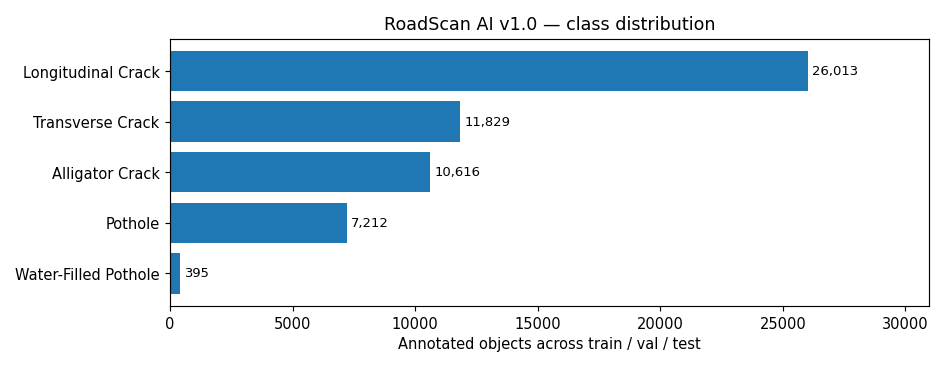

In [ ]:
# A small, presentation-ready chart that works even without the 10 GB image archive.
import matplotlib.pyplot as plt

reported_counts = pd.Series(
    {CLASS_NAMES[i]: n for i, n in enumerate([26013, 11829, 10616, 7212, 395])},
    name="objects",
)
ax = reported_counts.sort_values().plot.barh(figsize=(9, 3.5), legend=False)
ax.set_xlabel("Annotated objects across train / val / test")
ax.set_ylabel("")
ax.set_title("RoadScan AI v1.0 — class distribution")
for index, value in enumerate(reported_counts.sort_values()):
    ax.text(value + 180, index, f"{value:,}", va="center", fontsize=9)
ax.set_xlim(0, max(reported_counts) * 1.19)
plt.tight_layout()
plt.show()

## 11 · Remaining limitations and next milestone

**Ready for a small YOLO11 training smoke test, but not yet a final benchmark dataset.**

1. **Original RDD class mapping:** confirm source-class semantics; review annotations that became empty when original class `3` was excluded.
2. **Near-duplicate leakage:** SHA-256 catches identical file bytes only, not visually similar scenes or neighboring video frames.
3. **Water-filled pothole imbalance:** only **265 training objects** and **42 test objects** belong to class 4. Interpret per-class recall and mAP carefully; more diverse examples would improve confidence.
4. **Remaining visual edge cases:** `Pothole-053` and `Pothole-527` were flagged during review and may warrant another inspection.
5. **Dataset portability:** the generated `data.yaml` contains a path from the machine that built it. Update `path:` to the extracted `RoadScan_Final` directory when using another computer (Windows or macOS).
6. **Archiving and licensing:** the large image archive is intentionally excluded from normal Git commits. Before publicly distributing the complete dataset, verify redistribution rights for both source datasets.

**Next experiment:** run a short YOLO11n training sanity check on the RTX 4060, then address the remaining evaluation-quality issues before reporting final model metrics.